# Classificação de ocorrências de roubo e furto de celulares — São Paulo (2025)

**Objetivo:** classificar uma ocorrência já registrada como **roubo** ou **furto**. O modelo não estima a chance de um crime acontecer.

**Base:** arquivo Excel original da SSP-SP, aba `CELULAR_2025`, disponibilizado pela Secretaria da Segurança Pública de São Paulo. A base possui abas auxiliares `METODOLOGIA` e `DICIONARIO DE DADOS`.

**Critérios alinhados ao enunciado:** recorte dos fatos na capital; rótulo derivado de `RUBRICA`; exclusão de registros ambíguos; remoção de duplicidades por boletim; variáveis de entrada justificadas; separação treino/validação/teste; comparação de três MLPs; métricas, curvas, matriz de confusão e análise de overfitting.

> Execute as células em ordem no Google Colab. Quando solicitado, envie o XLSX original.

### 1. Bibliotecas utilizadas

Nesta etapa, foram instaladas e importadas as bibliotecas necessárias para o desenvolvimento do projeto.

- **Pandas:** manipulação e análise dos dados.
- **NumPy:** operações numéricas.
- **Matplotlib e Seaborn:** criação de gráficos e visualizações.
- **Scikit-learn:** preparação dos dados, divisão das amostras e cálculo das métricas.
- **TensorFlow/Keras:** construção e treinamento das redes neurais MLP.

Essas ferramentas permitem realizar todas as etapas do experimento, desde a preparação da base até a avaliação do modelo.

In [1]:
!pip -q install -q openpyxl scikit-learn tensorflow seaborn joblib

import os, re, unicodedata, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Pandas:", pd.__version__)

TensorFlow: 2.21.0
Pandas: 2.2.3


### 2. Carregamento da base de dados

Para o desenvolvimento do projeto, foi utilizada a base pública de celulares subtraídos da Secretaria da Segurança Pública do Estado de São Paulo (SSP-SP), referente ao ano de 2025.

O arquivo possui 383.635 registros e 55 colunas, contendo informações sobre as ocorrências, como município, bairro, natureza da ocorrência, período e tipo de local.

A base foi escolhida por apresentar registros que permitem distinguir ocorrências de roubo e furto, atendendo ao objetivo da atividade.

In [2]:
uploaded = files.upload()
xlsx_path = next((name for name in uploaded if name.lower().endswith(".xlsx")), None)
if xlsx_path is None:
    raise FileNotFoundError("Envie o arquivo XLSX da base de celulares subtraídos.")

df_raw = pd.read_excel(xlsx_path, sheet_name="CELULAR_2025", engine="openpyxl")
print("Dimensões originais:", df_raw.shape)
display(df_raw.head())
print("\nColunas disponíveis:")
print(df_raw.columns.tolist())

Saving CelularesSubtraidos_2025.xlsx to CelularesSubtraidos_2025.xlsx
Dimensões originais: (383635, 55)


,ID_DELEGACIA,NOME_DEPARTAMENTO,NOME_SECCIONAL,NOME_DELEGACIA,NOME_MUNICIPIO,ANO_BO,NUM_BO,VERSAO,NOME_DEPARTAMENTO_CIRC,NOME_SECCIONAL_CIRC,...,QUANTIDADE_OBJETO,MARCA_OBJETO,FLAG_BLOQUEIO,FLAG_DESBLOQUEIO,MES_REGISTRO_BO,ANO_REGISTRO_BO,CMD,BTL,CIA,CD_IBGE
0,900020,DIPOL - DEPTO DE INTELIGENCIA,DELEGACIA ELETRONICA,DELEGACIA ELETRONICA,S.PAULO,2025,AA1691,1,DECAP,DEL.SEC.1º CENTRO,...,1,Xiaomi,S,N,1,2025,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308
1,900021,DIPOL - DEPTO DE INTELIGENCIA,DELEGACIA ELETRONICA,DELEGACIA ELETRONICA 1,S.PAULO,2025,AA2064,1,DECAP,DEL.SEC.1º CENTRO,...,1,Apple,S,N,1,2025,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308
2,900020,DIPOL - DEPTO DE INTELIGENCIA,DELEGACIA ELETRONICA,DELEGACIA ELETRONICA,S.PAULO,2025,AA2458,1,DECAP,DEL.SEC.1º CENTRO,...,1,Motorola,S,N,1,2025,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308
3,900020,DIPOL - DEPTO DE INTELIGENCIA,DELEGACIA ELETRONICA,DELEGACIA ELETRONICA,S.PAULO,2025,AA2520,1,DECAP,DEL.SEC.1º CENTRO,...,1,Samsung,S,N,1,2025,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308
4,900020,DIPOL - DEPTO DE INTELIGENCIA,DELEGACIA ELETRONICA,DELEGACIA ELETRONICA,S.PAULO,2025,AA2537,1,DECAP,DEL.SEC.1º CENTRO,...,1,Apple,S,N,1,2025,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308



Colunas disponíveis:
['ID_DELEGACIA', 'NOME_DEPARTAMENTO', 'NOME_SECCIONAL', 'NOME_DELEGACIA', 'NOME_MUNICIPIO', 'ANO_BO', 'NUM_BO', 'VERSAO', 'NOME_DEPARTAMENTO_CIRC', 'NOME_SECCIONAL_CIRC', 'NOME_DELEGACIA_CIRC', 'NOME_MUNICIPIO_CIRC', 'DATA_OCORRENCIA_BO', 'HORA_OCORRENCIA', 'DESCRICAO_APRESENTACAO', 'DATAHORA_REGISTRO_BO', 'DATA_COMUNICACAO_BO', 'DATAHORA_IMPRESSAO_BO', 'DESCR_PERIODO', 'AUTORIA_BO', 'FLAG_INTOLERANCIA', 'TIPO_INTOLERANCIA', 'FLAG_FLAGRANTE', 'FLAG_STATUS', 'DESC_LEI', 'FLAG_ATO_INFRACIONAL', 'RUBRICA', 'DESCR_CONDUTA', 'DESDOBRAMENTO', 'CIRCUNSTANCIA', 'DESCR_TIPOLOCAL', 'DESCR_SUBTIPOLOCAL', 'CIDADE', 'BAIRRO', 'CEP', 'LOGRADOURO_VERSAO', 'LOGRADOURO', 'NUMERO_LOGRADOURO', 'LATITUDE', 'LONGITUDE', 'CONT_OBJETO', 'DESCR_MODO_OBJETO', 'DESCR_TIPO_OBJETO', 'DESCR_SUBTIPO_OBJETO', 'DESCR_UNIDADE', 'QUANTIDADE_OBJETO', 'MARCA_OBJETO', 'FLAG_BLOQUEIO', 'FLAG_DESBLOQUEIO', 'MES_REGISTRO_BO', 'ANO_REGISTRO_BO', 'CMD', 'BTL', 'CIA', 'CD_IBGE']


### 3. Análise das naturezas das ocorrências

Inicialmente, foi analisada a coluna RUBRICA, responsável por identificar a natureza da ocorrência registrada.

Foram identificadas 169.628 ocorrências de furto e 135.763 ocorrências de roubo na base original.

Também foram encontradas outras naturezas, como perda, extravio, estelionato e localização de veículos.

Como o objetivo do projeto é realizar uma classificação binária, foram selecionadas apenas as ocorrências de roubo e furto. As demais naturezas foram excluídas do experimento.

In [3]:
colunas_necessarias = [
    "CIDADE", "RUBRICA", "BAIRRO", "DESCR_PERIODO",
    "DESCR_TIPOLOCAL", "DESCR_SUBTIPOLOCAL",
    "DATA_OCORRENCIA_BO", "HORA_OCORRENCIA",
    "NOME_DELEGACIA", "ANO_BO", "NUM_BO"
]
faltantes = [c for c in colunas_necessarias if c not in df_raw.columns]
if faltantes:
    raise KeyError(f"Colunas esperadas não encontradas: {faltantes}")

print("Valores mais frequentes em CIDADE:")
display(df_raw["CIDADE"].value_counts(dropna=False).head(15))
print("\nValores mais frequentes em RUBRICA:")
display(df_raw["RUBRICA"].value_counts(dropna=False).head(30))

Valores mais frequentes em CIDADE:


,count
CIDADE,
S.PAULO,216129
GUARULHOS,10821
CAMPINAS,9380
S.ANDRE,7720
S.BERNARDO DO CAMPO,6659
OSASCO,6612
PRAIA GRANDE,4100
RIBEIRAO PRETO,3996
S.VICENTE,3813



Valores mais frequentes em RUBRICA:


,count
RUBRICA,
Furto (art. 155),169628
Roubo (art. 157),135763
Perda/Extravio,52074
Localização/Apreensão e Entrega de veículo,6486
Outros não criminal,1993
Estelionato (art. 171),1928
Localização/Apreensão de veículo,1650
Lesão corporal (art. 129),1536
Extorsão (art. 158),1156


**Análise dos resultados**

A distribuição das naturezas demonstra que as ocorrências de furto representam a maior parte dos registros, com 169.628 casos, enquanto os roubos correspondem a 135.763 registros.

Juntas, essas duas categorias totalizam 305.391 ocorrências, representando a maior parte da base analisada. Também foram identificadas outras naturezas, como perda, extravio e estelionato.

Essa análise justifica a seleção de roubo e furto como classes do projeto, permitindo transformar o problema em uma tarefa de classificação binária.

### 4. Limpeza, recorte geográfico e definição da variável-alvo

Nesta etapa, foi realizado o recorte geográfico para manter somente as ocorrências da cidade de São Paulo, utilizando a coluna CIDADE, que representa o município onde o fato ocorreu.

Também foi realizada a normalização dos textos, removendo diferenças de acentuação, espaços e letras maiúsculas ou minúsculas.

A variável-alvo foi criada a partir da coluna RUBRICA, utilizando a seguinte codificação:

- 0: Furto.
- 1: Roubo.

Registros que não correspondiam claramente a uma dessas duas classes foram descartados.

Após os filtros, foram obtidos 183.812 registros, sendo 106.406 furtos e 77.406 roubos.

In [4]:

def normalizar_texto(valor):
    if pd.isna(valor):
        return ""

    texto = str(valor).strip().upper()
    texto = unicodedata.normalize("NFKD", texto)
    texto = "".join(
        ch for ch in texto
        if not unicodedata.combining(ch)
    )
    texto = re.sub(r"\s+", " ", texto)

    return texto


# Criando uma cópia da base original
df = df_raw.copy()

# Normalizando os campos
df["CIDADE_NORM"] = df["CIDADE"].map(normalizar_texto)
df["RUBRICA_NORM"] = df["RUBRICA"].map(normalizar_texto)

# Filtrando registros da cidade de São Paulo
df_sp = df[
    df["CIDADE_NORM"].isin([
        "S.PAULO",
        "SAO PAULO",
        "SAO PAULO - SP",
        "SAO PAULO/SP"
    ])
].copy()


# Definindo a variável-alvo
# 0 = Furto | 1 = Roubo

def rotular_rubrica(valor):
    tem_roubo = bool(re.search(r"\bROUBO\b", valor))
    tem_furto = bool(re.search(r"\bFURTO\b", valor))

    if tem_roubo and not tem_furto:
        return 1

    if tem_furto and not tem_roubo:
        return 0

    return np.nan


# Aplicando a classificação
df_sp["ALVO"] = df_sp["RUBRICA_NORM"].map(rotular_rubrica)

# Removendo registros que não são roubo nem furto
df_sp = df_sp.dropna(subset=["ALVO"]).copy()

# Convertendo o alvo para inteiro
df_sp["ALVO"] = df_sp["ALVO"].astype("int8")

# Preserva a base filtrada original para que a etapa 5 possa ser reexecutada
# sem acumular exclusões de execuções anteriores.
df_sp_base = df_sp.copy()


# Exibindo os resultados
print("Registros após o recorte de São Paulo e filtro de roubo/furto:", len(df_sp))

print("\nDistribuição das classes (0 = furto; 1 = roubo):")

display(
    df_sp["ALVO"]
    .value_counts()
    .rename(index={0: "Furto", 1: "Roubo"})
    .to_frame("Quantidade")
)

print("\nProporção das classes:")

display(
    df_sp["ALVO"]
    .value_counts(normalize=True)
    .rename(index={0: "Furto", 1: "Roubo"})
    .to_frame("Proporção")
)


Registros após o recorte de São Paulo e filtro de roubo/furto: 183812

Distribuição das classes (0 = furto; 1 = roubo):


,Quantidade
ALVO,
Furto,106406
Roubo,77406



Proporção das classes:


,Proporção
ALVO,
Furto,0.578885
Roubo,0.421115


### 5. Tratamento de duplicidades por boletim

A base pode apresentar várias linhas relacionadas a um mesmo boletim de ocorrência, principalmente devido aos diferentes objetos associados ao registro.

O agrupamento utiliza as colunas `NOME_DELEGACIA`, `ANO_BO` e `NUM_BO`, conforme a metodologia consultada na planilha da SSP-SP. Antes da consolidação, são removidos registros sem identificação completa e boletins que apresentam conflito entre as classes Furto e Roubo.

Os totais de registros iniciais, boletins ambíguos removidos, boletins finais e diferenças são apresentados pela célula de código abaixo. Esses valores devem ser atualizados conforme a execução da base.

In [5]:
# Sempre parte da base filtrada original do tópico 4.
# Isso evita que uma nova execução da célula acumule filtros anteriores.
if "df_sp_base" not in globals():
    raise RuntimeError("Execute primeiro o Tópico 4 para criar df_sp_base.")

df_processamento = df_sp_base.copy()
antes = len(df_processamento)

# Identificação do boletim conforme a aba METODOLOGIA da planilha SSP-SP.
chaves_bo = [
    "NOME_DELEGACIA",
    "ANO_BO",
    "NUM_BO"
]

# Remove registros sem identificação completa.
df_processamento = df_processamento.dropna(subset=chaves_bo).copy()

# Identifica boletins que possuem mais de uma classe (furto e roubo).
classes_por_bo = (
    df_processamento.groupby(chaves_bo)["ALVO"]
    .nunique()
)

# Seleciona os boletins com classificação conflitante.
bo_ambiguos = classes_por_bo[classes_por_bo > 1].index

# Remove todos os registros dos boletins ambíguos.
if len(bo_ambiguos) > 0:
    idx_ambiguos = pd.MultiIndex.from_frame(
        df_processamento[chaves_bo]
    ).isin(bo_ambiguos)

    df_processamento = df_processamento.loc[~idx_ambiguos].copy()

# Atributos que serão mantidos no modelo.
features_candidatas = [
    "BAIRRO",
    "DESCR_PERIODO",
    "DESCR_TIPOLOCAL",
    "DESCR_SUBTIPOLOCAL"
]

# Retorna a categoria mais frequente, ignorando valores vazios.
def moda_segura(serie):
    valores = serie.dropna().astype(str).str.strip()
    valores = valores[valores.ne("")]

    if valores.empty:
        return np.nan

    modas = valores.mode()
    return modas.iloc[0] if not modas.empty else valores.iloc[0]

# Consolida os atributos de cada boletim.
agregacoes = {coluna: moda_segura for coluna in features_candidatas}
agregacoes["ALVO"] = "first"

df_model = (
    df_processamento.groupby(chaves_bo, as_index=False)
    .agg(agregacoes)
)

print("Linhas antes do processamento:", antes)
print("Boletins após remoção de ambiguidades e agrupamento:", len(df_model))
print("Registros sem identificação completa:", antes - len(df_sp_base.dropna(subset=chaves_bo)))
print("Boletins ambíguos removidos:", len(bo_ambiguos))
print("Boletins finais:", len(df_model))
print("Diferença entre linhas iniciais e boletins finais:", antes - len(df_model))
display(df_model.head())


Linhas antes do processamento: 183812
Boletins após remoção de ambiguidades e agrupamento: 161581
Registros sem identificação completa: 0
Boletins ambíguos removidos: 44
Boletins finais: 161581
Diferença entre linhas iniciais e boletins finais: 22231


,NOME_DELEGACIA,ANO_BO,NUM_BO,BAIRRO,DESCR_PERIODO,DESCR_TIPOLOCAL,DESCR_SUBTIPOLOCAL,ALVO
0,01ª DDM CENTRO,2025,BF2269,CAMBUCI,A tarde,Entidade Assistencial,Outros,0
1,01ª DDM CENTRO,2025,BG7076,JARDIM DAS BANDEIRAS,A noite,Hospedagem,Pensão/Estalagem/Hospedaria,0
2,01ª DDM CENTRO,2025,BI9724,CAMBUCI,NaN,Via Pública,Via Pública,1
3,01ª DDM CENTRO,2025,BT6468,CENTRO HISTÓRICO DE SÃO PAULO,NaN,Hospedagem,Hotel,0
4,01ª DDM CENTRO,2025,BX1745,SE,NaN,Via Pública,Via Pública,0


### 6. Seleção dos atributos e análise exploratória

Foram selecionados quatro atributos para alimentar a rede neural:

- `BAIRRO`: região onde ocorreu o fato.
- `DESCR_PERIODO`: período do dia em que ocorreu a ocorrência.
- `DESCR_TIPOLOCAL`: categoria do local.
- `DESCR_SUBTIPOLOCAL`: descrição mais específica do local.

Essas variáveis representam características da ocorrência que podem auxiliar na diferenciação entre roubo e furto.

Para manter o experimento compatível com o tempo de processamento, foi definida uma amostra máxima de 20.000 registros, preservando a proporção das classes por meio de amostragem estratificada. A distribuição efetivamente obtida é exibida pela célula de código.

**Análise dos resultados**

A distribuição apresentada na tabela e no gráfico mostra a quantidade de ocorrências de furto e roubo selecionadas para o experimento. A amostragem é estratificada, preservando a proporção das classes da base consolidada.

Os números desta análise devem ser interpretados a partir da saída efetiva da execução do notebook.

Distribuição antes da amostragem:


,Quantidade
ALVO,
Furto,101945
Roubo,59636


Total utilizado no experimento: 20000


,Quantidade
ALVO,
Furto,12618
Roubo,7382


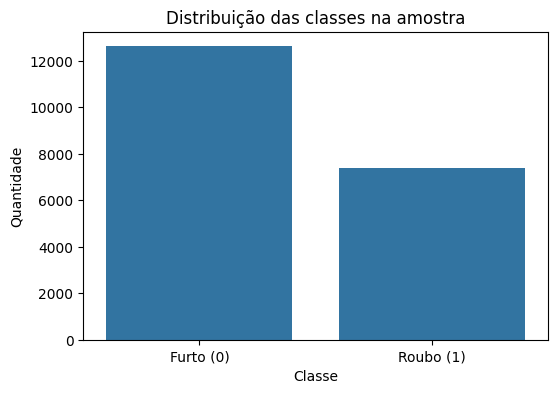


BAIRRO: 1009 categorias

DESCR_PERIODO: 5 categorias

DESCR_TIPOLOCAL: 27 categorias

DESCR_SUBTIPOLOCAL: 113 categorias


In [6]:
# Mantém somente atributos previstos no experimento e remove linhas sem alvo.
FEATURES = ["BAIRRO", "DESCR_PERIODO", "DESCR_TIPOLOCAL", "DESCR_SUBTIPOLOCAL"]
df_model = df_model.dropna(subset=["ALVO"]).copy()
for c in FEATURES:
    df_model[c] = df_model[c].replace(r"^\s*$", np.nan, regex=True)

print("Distribuição antes da amostragem:")
display(df_model["ALVO"].value_counts().rename(index={0:"Furto",1:"Roubo"}).to_frame("Quantidade"))

MAX_REGISTROS = 20000

if len(df_model) > MAX_REGISTROS:
    df_model, _ = train_test_split(
        df_model,
        train_size=MAX_REGISTROS,
        stratify=df_model["ALVO"],
        random_state=SEED
    )

df_model = df_model.reset_index(drop=True)

print("Total utilizado no experimento:", len(df_model))
display(
    df_model["ALVO"]
    .value_counts()
    .sort_index()
    .rename(index={0: "Furto", 1: "Roubo"})
    .to_frame("Quantidade")
)

plt.figure(figsize=(6,4))
sns.countplot(data=df_model, x="ALVO")
plt.xticks([0,1], ["Furto (0)", "Roubo (1)"])
plt.title("Distribuição das classes na amostra")
plt.xlabel("Classe")
plt.ylabel("Quantidade")
plt.show()

for coluna in FEATURES:
    print(f"\n{coluna}: {df_model[coluna].nunique(dropna=True)} categorias")

### 7. Separação dos conjuntos de dados

Os dados foram divididos em três conjuntos:

- 70% para treinamento (14.000 registros).
- 15% para validação (3.000 registros).
- 15% para teste (3.000 registros).

A separação foi realizada de forma estratificada, preservando a proporção entre as classes de roubo e furto.

O conjunto de treinamento é utilizado para ensinar a rede neural, o conjunto de validação auxilia na comparação e seleção das arquiteturas, e o conjunto de teste é reservado para avaliar o desempenho final do modelo.

In [7]:
X = df_model[FEATURES].copy()
y = df_model["ALVO"].astype("int32").copy()

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

print("Treino:", X_train.shape, "Validação:", X_val.shape, "Teste:", X_test.shape)
for nome, alvo in [("Treino",y_train),("Validação",y_val),("Teste",y_test)]:
    print(nome, alvo.value_counts(normalize=True).sort_index().round(3).to_dict())

Treino: (14000, 4) Validação: (3000, 4) Teste: (3000, 4)
Treino {0: 0.631, 1: 0.369}
Validação {0: 0.631, 1: 0.369}
Teste {0: 0.631, 1: 0.369}


### 8. Pré-processamento dos dados

Como os atributos selecionados são categóricos, foi necessário transformá-los em valores numéricos para que pudessem ser utilizados pela rede neural.

Para isso, foi aplicado o **One-Hot Encoding**, técnica que transforma cada categoria em uma coluna indicadora (0 ou 1). Também foi utilizado o preenchimento de valores ausentes pela categoria mais frequente.

Após a aplicação do One-Hot Encoding, foram obtidas 1.009 variáveis numéricas, correspondentes às categorias identificadas no conjunto de treinamento. A mesma transformação foi aplicada aos conjuntos de validação e teste, mantendo as dimensões de entrada consistentes.

**Não foi aplicado StandardScaler.** Após o One-Hot Encoding, as entradas são variáveis binárias (0 ou 1), portanto já estão em uma escala comum. A padronização não era necessária para este conjunto de atributos. O pré-processador foi ajustado somente com os dados de treinamento, evitando vazamento de informação para validação e teste.


In [8]:
try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:  # compatibilidade com versões antigas do scikit-learn
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

preprocessador = ColumnTransformer(
    transformers=[
        ("categoricas", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", encoder)
        ]), FEATURES)
    ],
    remainder="drop"
)

X_train_p = preprocessador.fit_transform(X_train).astype("float32")
X_val_p = preprocessador.transform(X_val).astype("float32")
X_test_p = preprocessador.transform(X_test).astype("float32")

print("Dimensão após one-hot encoding:", X_train_p.shape[1])
print("Treino/validação/teste:", X_train_p.shape, X_val_p.shape, X_test_p.shape)

encoder_fitted = (
    preprocessador
    .named_transformers_["categoricas"]
    .named_steps["onehot"]
)

print("\nCategorias aprendidas por variável:")

for nome, categorias in zip(FEATURES, encoder_fitted.categories_):
    print(f"{nome}: {len(categorias)}")

print("\nTotal de categorias:", sum(
    len(categorias) for categorias in encoder_fitted.categories_
))

print("Total de colunas geradas:", X_train_p.shape[1])

Dimensão após one-hot encoding: 1009
Treino/validação/teste: (14000, 1009) (3000, 1009) (3000, 1009)

Categorias aprendidas por variável:
BAIRRO: 877
DESCR_PERIODO: 5
DESCR_TIPOLOCAL: 26
DESCR_SUBTIPOLOCAL: 101

Total de categorias: 1009
Total de colunas geradas: 1009


### 9. Construção e treinamento das redes MLP

Foram desenvolvidas três arquiteturas diferentes de redes neurais Multilayer Perceptron (MLP), variando a quantidade de camadas ocultas e neurônios.

- MLP 1: uma camada oculta com 32 neurônios.
- MLP 2: duas camadas ocultas com 64 e 32 neurônios.
- MLP 3: três camadas ocultas com 128, 64 e 32 neurônios, utilizando Dropout de 20%.

As redes utilizaram a função de ativação ReLU nas camadas ocultas e Sigmoid na camada de saída.

Foi utilizada a função de perda Binary Crossentropy e o otimizador Adam.

O treinamento foi realizado por até 40 épocas, com batch size de 128 e Early Stopping para interromper o treinamento quando não houvesse melhora na validação.

In [9]:
def construir_mlp(input_dim, camadas, learning_rate=0.001, dropout=0.0):
    modelo = tf.keras.Sequential()
    modelo.add(tf.keras.layers.Input(shape=(input_dim,)))
    for unidades in camadas:
        modelo.add(tf.keras.layers.Dense(unidades, activation="relu"))
        if dropout > 0:
            modelo.add(tf.keras.layers.Dropout(dropout))
    modelo.add(tf.keras.layers.Dense(1, activation="sigmoid"))
    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[tf.keras.metrics.BinaryAccuracy(name="accuracy")]
    )
    return modelo

arquiteturas = {
    "MLP 1 — 1 camada (32)": {"camadas":[32], "dropout":0.0},
    "MLP 2 — 2 camadas (64, 32)": {"camadas":[64,32], "dropout":0.0},
    "MLP 3 — 3 camadas + dropout (128, 64, 32)": {"camadas":[128,64,32], "dropout":0.20}
}

modelos = {}
historicos = {}
resultados_validacao = []

for nome, config in arquiteturas.items():
    print("\nTreinando:", nome)
    modelo = construir_mlp(
        input_dim=X_train_p.shape[1],
        camadas=config["camadas"],
        dropout=config["dropout"]
    )
    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True
    )
    history = modelo.fit(
        X_train_p, y_train,
        validation_data=(X_val_p, y_val),
        epochs=40,
        batch_size=128,
        callbacks=[early_stop],
        verbose=0
    )
    prob_val = modelo.predict(X_val_p, verbose=0).ravel()
    pred_val = (prob_val >= 0.5).astype(int)
    metricas = {
        "Arquitetura": nome,
        "Acurácia": accuracy_score(y_val, pred_val),
        "Precision": precision_score(y_val, pred_val, zero_division=0),
        "Recall": recall_score(y_val, pred_val, zero_division=0),
        "F1-score": f1_score(y_val, pred_val, zero_division=0),
        "Épocas executadas": len(history.history["loss"])
    }
    modelos[nome] = modelo
    historicos[nome] = history
    resultados_validacao.append(metricas)
    print(metricas)

comparacao = pd.DataFrame(resultados_validacao).sort_values("F1-score", ascending=False)
display(comparacao)


Treinando: MLP 1 — 1 camada (32)
{'Arquitetura': 'MLP 1 — 1 camada (32)', 'Acurácia': 0.7696666666666667, 'Precision': 0.6805194805194805, 'Recall': 0.7093862815884476, 'F1-score': 0.694653115333628, 'Épocas executadas': 10}

Treinando: MLP 2 — 2 camadas (64, 32)
{'Arquitetura': 'MLP 2 — 2 camadas (64, 32)', 'Acurácia': 0.7706666666666667, 'Precision': 0.6948051948051948, 'Recall': 0.6759927797833934, 'F1-score': 0.6852698993595608, 'Épocas executadas': 7}

Treinando: MLP 3 — 3 camadas + dropout (128, 64, 32)
{'Arquitetura': 'MLP 3 — 3 camadas + dropout (128, 64, 32)', 'Acurácia': 0.769, 'Precision': 0.699711260827719, 'Recall': 0.6561371841155235, 'F1-score': 0.6772240335351654, 'Épocas executadas': 8}


,Arquitetura,Acurácia,Precision,Recall,F1-score,Épocas executadas
0,MLP 1 — 1 camada (32),0.769667,0.680519,0.709386,0.694653,10
1,"MLP 2 — 2 camadas (64, 32)",0.770667,0.694805,0.675993,0.685270,7
2,"MLP 3 — 3 camadas + dropout (128, 64, 32)",0.769000,0.699711,0.656137,0.677224,8


**Análise dos resultados**

A comparação das três arquiteturas é realizada com as métricas de acurácia, precision, recall e F1-score no conjunto de validação. A tabela produzida pelo código apresenta os resultados de cada MLP.

A arquitetura selecionada é aquela que obtém o maior F1-score na validação. A escolha considera o equilíbrio entre precision e recall, e não somente a acurácia.

### 10. Seleção da melhor arquitetura

Após o treinamento, as três arquiteturas são comparadas utilizando acurácia, precision, recall e F1-score no conjunto de validação.

A arquitetura com maior F1-score na validação é selecionada para a avaliação final. O conjunto de teste permanece reservado e não participa da escolha do modelo.

In [10]:
melhor_nome = comparacao.iloc[0]["Arquitetura"]
melhor_modelo = modelos[melhor_nome]
melhor_historico = historicos[melhor_nome]
print("Arquitetura selecionada:", melhor_nome)

Arquitetura selecionada: MLP 1 — 1 camada (32)


### 11. Análise das curvas de treinamento e validação

São analisadas as curvas de acurácia e perda da arquitetura selecionada.

A comparação entre as curvas de treinamento e validação permite observar a evolução do aprendizado e identificar possíveis sinais de overfitting ou underfitting. A célula seguinte informa também a melhor época segundo a menor perda de validação.

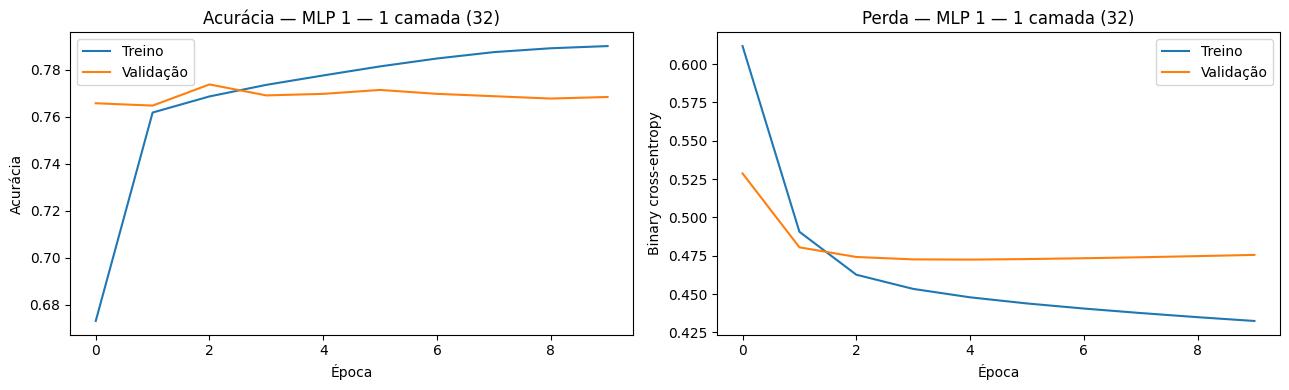

Épocas executadas: 10
Última perda de treino: 0.4324
Última perda de validação: 0.4755
Melhor época pela perda de validação: 5
Menor perda de validação: 0.4725


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13,4))
axes[0].plot(melhor_historico.history["accuracy"], label="Treino")
axes[0].plot(melhor_historico.history["val_accuracy"], label="Validação")
axes[0].set_title("Acurácia — " + melhor_nome)
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Acurácia")
axes[0].legend()

axes[1].plot(melhor_historico.history["loss"], label="Treino")
axes[1].plot(melhor_historico.history["val_loss"], label="Validação")
axes[1].set_title("Perda — " + melhor_nome)
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Binary cross-entropy")
axes[1].legend()
plt.tight_layout()
plt.show()

ultima = len(melhor_historico.history["loss"]) - 1
melhor_epoca = int(np.argmin(melhor_historico.history["val_loss"])) + 1

print("Épocas executadas:", len(melhor_historico.history["loss"]))
print("Última perda de treino:", round(melhor_historico.history["loss"][ultima], 4))
print("Última perda de validação:", round(melhor_historico.history["val_loss"][ultima], 4))
print("Melhor época pela perda de validação:", melhor_epoca)
print("Menor perda de validação:", round(min(melhor_historico.history["val_loss"]), 4))

In [12]:
# Interpretação quantitativa das curvas da arquitetura selecionada
loss_treino = melhor_historico.history["loss"]
loss_validacao = melhor_historico.history["val_loss"]
idx_melhor = int(np.argmin(loss_validacao))
idx_ultima = len(loss_validacao) - 1
melhor_val = float(loss_validacao[idx_melhor])
ultima_val = float(loss_validacao[idx_ultima])
ultima_treino = float(loss_treino[idx_ultima])
print("Interpretação automática das curvas:")
print(f"- Menor perda de validação: {melhor_val:.4f} na época {idx_melhor + 1}.")
print(f"- Perda de validação na última época executada: {ultima_val:.4f}.")
print(f"- Perda de treinamento na última época executada: {ultima_treino:.4f}.")
if idx_ultima > idx_melhor and ultima_val > melhor_val + 1e-4 and ultima_treino < loss_treino[idx_melhor]:
    print("- Há sinal de possível overfitting após a melhor época: a perda de validação aumentou enquanto a perda de treinamento continuou diminuindo.")
elif abs(ultima_val - melhor_val) <= 1e-4:
    print("- A perda de validação permaneceu próxima do seu melhor valor até o encerramento; não há aumento relevante após o mínimo.")
else:
    print("- Não foi identificado, por este critério isolado, um aumento claro da perda de validação após o mínimo. Confira também a distância entre as curvas de acurácia e perda.")
print("- O EarlyStopping restaura os pesos da melhor época de validação para a avaliação e exportação do modelo.")


Interpretação automática das curvas:
- Menor perda de validação: 0.4725 na época 5.
- Perda de validação na última época executada: 0.4755.
- Perda de treinamento na última época executada: 0.4324.
- Há sinal de possível overfitting após a melhor época: a perda de validação aumentou enquanto a perda de treinamento continuou diminuindo.
- O EarlyStopping restaura os pesos da melhor época de validação para a avaliação e exportação do modelo.


**Análise dos resultados**

A interpretação das curvas deve considerar os resultados impressos logo após os gráficos. A melhor época é definida pela menor perda no conjunto de validação. Como foi utilizado `EarlyStopping` com `restore_best_weights=True`, os pesos restaurados ao final do treinamento correspondem à melhor época de validação, mesmo que o histórico apresente épocas posteriores.

A célula seguinte compara a perda de validação na melhor época com a perda da última época executada. Se a perda de validação aumentar depois do seu mínimo enquanto a perda de treinamento continuar diminuindo, isso é um sinal de possível **overfitting**. Se as perdas de treinamento e validação permanecerem altas e próximas, pode haver **underfitting**. A conclusão deve ser feita com base nos valores e nas curvas da execução atual.


### 12. Avaliação final do modelo

Após selecionar a melhor arquitetura com base no conjunto de validação, é realizada a avaliação final utilizando o conjunto de teste, que não participou do treinamento nem da escolha do modelo.

São apresentados acurácia, precision, recall, F1-score, relatório de classificação e matriz de confusão. A saída da execução é a referência para os valores finais do relatório.

,Acurácia,Precision,Recall,F1-score
MLP 1 — 1 camada (32),0.758,0.661304,0.70551,0.682692


              precision    recall  f1-score   support

       Furto       0.82      0.79      0.80      1893
       Roubo       0.66      0.71      0.68      1107

    accuracy                           0.76      3000
   macro avg       0.74      0.75      0.74      3000
weighted avg       0.76      0.76      0.76      3000



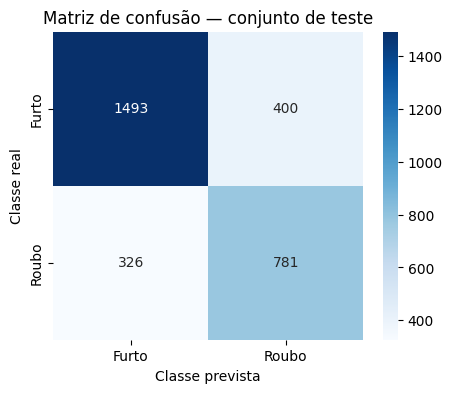

In [13]:
prob_test = melhor_modelo.predict(X_test_p, verbose=0).ravel()
pred_test = (prob_test >= 0.5).astype(int)

metricas_teste = {
    "Acurácia": accuracy_score(y_test, pred_test),
    "Precision": precision_score(y_test, pred_test, zero_division=0),
    "Recall": recall_score(y_test, pred_test, zero_division=0),
    "F1-score": f1_score(y_test, pred_test, zero_division=0)
}
display(pd.DataFrame([metricas_teste], index=[melhor_nome]))
print(classification_report(
    y_test, pred_test, target_names=["Furto", "Roubo"], zero_division=0
))

cm = confusion_matrix(y_test, pred_test, labels=[0,1])
plt.figure(figsize=(5,4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Furto", "Roubo"],
    yticklabels=["Furto", "Roubo"]
)
plt.title("Matriz de confusão — conjunto de teste")
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.show()

**Análise dos resultados**

A avaliação final utiliza os 3.000 registros reservados para teste. A MLP 1 obteve acurácia de **75,80%**, precision de **66,13%**, recall de **70,55%** e F1-score de **68,27%**.

A matriz de confusão demonstra que o modelo classificou corretamente **1.493 ocorrências de furto** e **781 ocorrências de roubo**. Entretanto, **400 furtos** foram classificados como roubo e **326 roubos** foram classificados como furto.

Os resultados indicam que o modelo conseguiu identificar ambas as classes, mas ainda apresenta erros de classificação. Para a classe Roubo, o recall de 70,55% indica que o modelo identificou corretamente 781 dos 1.107 registros reais dessa classe.

A interpretação utiliza os valores da execução mais recente do notebook.


## 13. Análise crítica e limitações

**Comparação das arquiteturas:** a escolha da MLP é baseada no F1-score do conjunto de validação. A comparação também considera acurácia, precision e recall.

**Generalização:** o desempenho no conjunto de teste é utilizado para avaliar a capacidade de generalização do modelo após a seleção da arquitetura.

**Limitações:** o modelo classifica registros de ocorrências já registradas e não prevê onde ou quando crimes acontecerão. Seu desempenho depende da qualidade, completude e representatividade dos dados e dos atributos selecionados. A amostra utilizada no experimento também limita a abrangência da avaliação.

**Uso responsável:** os resultados são experimentais e não devem ser utilizados isoladamente para decisões policiais, investigativas ou sobre indivíduos.

### 14. Exportação do modelo e do pré-processador

Após o treinamento e a avaliação, o modelo selecionado e o pré-processador são exportados para utilização em uma aplicação externa.

São gerados três arquivos:

- `modelo_mlp_roubo_furto.keras`: contém a rede neural treinada.
- `preprocessador.joblib`: contém as transformações utilizadas nos atributos.
- `metadados_modelo.json`: registra os atributos de entrada, as classes e a arquitetura selecionada.

A célula de exportação também realiza uma verificação básica de carregamento e previsão para testar a integridade dos artefatos.

In [14]:
import joblib, json

melhor_modelo.save("modelo_mlp_roubo_furto.keras")
joblib.dump(preprocessador, "preprocessador.joblib")

metadados = {
    "features": FEATURES,
    "classes": {"0":"Furto", "1":"Roubo"},
    "arquitetura_escolhida": melhor_nome,
    "limiar_classificacao": 0.5,
    "objetivo": "Classificar uma ocorrência já registrada; não prever ocorrência futura."
}
with open("metadados_modelo.json", "w", encoding="utf-8") as f:
    json.dump(metadados, f, ensure_ascii=False, indent=2)

print("Arquivos gerados:")
print("- modelo_mlp_roubo_furto.keras")
print("- preprocessador.joblib")
print("- metadados_modelo.json")

# Verificação dos arquivos exportados: recarrega e executa uma previsão de teste.
modelo_recarregado = tf.keras.models.load_model("modelo_mlp_roubo_furto.keras")
preprocessador_recarregado = joblib.load("preprocessador.joblib")

amostra_teste = X_test.iloc[[0]]
amostra_processada = preprocessador_recarregado.transform(amostra_teste).astype("float32")
probabilidade = float(modelo_recarregado.predict(amostra_processada, verbose=0).ravel()[0])
classe_prevista = int(probabilidade >= metadados["limiar_classificacao"])

print("Verificação de exportação concluída.")
print("Probabilidade estimada para Roubo:", round(probabilidade, 4))
print("Classe prevista:", "Roubo" if classe_prevista == 1 else "Furto")


Arquivos gerados:
- modelo_mlp_roubo_furto.keras
- preprocessador.joblib
- metadados_modelo.json
Verificação de exportação concluída.
Probabilidade estimada para Roubo: 0.0156
Classe prevista: Furto


### 15. Referência da fonte

SECRETARIA DA SEGURANÇA PÚBLICA DO ESTADO DE SÃO PAULO (SSP-SP). Portal de Estatísticas — Consultas e Bases de Dados.

Disponível em: https://www.ssp.sp.gov.br/estatistica/consultas

Base utilizada: `CelularesSubtraidos_2025.xlsx`, aba `CELULAR_2025`, referente ao ano de 2025.

A metodologia e o dicionário de dados disponibilizados nas demais abas da planilha foram utilizados como apoio para compreender e selecionar as variáveis do experimento.

### 16. Integração do modelo à aplicação

Os arquivos exportados na etapa anterior são utilizados pela aplicação web para realizar novas classificações. O pré-processador aplica às entradas do usuário as mesmas transformações utilizadas durante o treinamento, e a rede neural retorna a classificação estimada entre Furto e Roubo.


In [15]:
from google.colab import files

files.download("modelo_mlp_roubo_furto.keras")
files.download("preprocessador.joblib")
files.download("metadados_modelo.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>